# 03 – Topic modelling med LDA

Den här notebooken använder **Latent Dirichlet Allocation (LDA)** som andra klustringsmetod och jämför resultatet med K-means (`02_kmeans.ipynb`).

### Hur LDA skiljer sig från K-means
- **K-means** placerar varje klagomål i *exakt ett* kluster.
- **LDA** antar att varje klagomål är en *blandning av flera ämnen*. Ett klagomål kan t.ex. vara 60 % "bedrägeri" och 40 % "bristande ärendehantering".

Enkelt förklarat: LDA letar efter grupper av ord som ofta förekommer tillsammans i samma texter. Varje sådan grupp blir ett **ämne** (topic). Modellen beräknar sedan hur mycket varje text handlar om varje ämne.

Det passar klagomålstexter bra, eftersom många klagomål handlar om flera saker samtidigt. Detta syntes i K-means, där det största klustret samlade texter som främst beskrev ett utdraget förlopp.

**Upplägg:**
1. Bag of Words
2. Träning av LDA med 14 ämnen
3. Tolkning av ämnena
4. Jämförelse med K-means

Alla slumpmässiga steg använder `random_state=42`.

## 1. Bag of Words

LDA kräver **Bag of Words**, dvs. hur många gånger varje ord förekommer i varje text, i stället för TF-IDF. LDA är en sannolikhetsmodell som beskriver hur texter "genereras" ord för ord, och den bygger därför på faktiska ordantal. TF-IDF-vikter är inte antal och passar inte modellens antaganden.

Samma textrensning och stoppordslista som i K-means används, så att metoderna kan jämföras rättvist.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

df = pd.read_parquet("../data/complaints_kmeans.parquet")
print("Antal klagomål:", len(df))

foretagsnamn = {
    "wells", "fargo", "chase", "jpmorgan", "paypal", "capital", "affirm",
    "mohela", "navient", "nelnet", "citi", "citibank", "synchrony",
    "amex", "barclays", "coinbase", "santander", "ally", "truist",
    "america", "venmo",
}
klagomalsord = {
    "told", "called", "received", "did", "company", "consumer",
    "information", "said", "asked", "stated", "contacted",
}
stoppord = list(ENGLISH_STOP_WORDS | foretagsnamn | klagomalsord)

bow = CountVectorizer(stop_words=stoppord, min_df=20, max_df=0.5)
X_bow = bow.fit_transform(df["text_clean"])
ord_lista = bow.get_feature_names_out()

print("Matrisens storlek:", X_bow.shape)

Antal klagomål: 101373
Matrisens storlek: (101373, 9189)


## 2. Träning av LDA

**Antal ämnen: 14**, samma som antalet kluster i K-means. Då jämförs metoderna på samma detaljnivå.

**Träning på ett stickprov:** modellen tränas på 30 000 slumpmässigt valda klagomål, eftersom LDA är beräkningstungt. Den tränade modellen används sedan för att beräkna ämnesfördelningen för *alla* klagomål. Stickprovet är tillräckligt stort för att fånga de vanliga ämnena.

In [2]:
from sklearn.decomposition import LatentDirichletAllocation

rng = np.random.default_rng(42)
urval = rng.choice(X_bow.shape[0], size=30_000, replace=False)

lda = LatentDirichletAllocation(
    n_components=14,
    learning_method="online",
    max_iter=10,
    random_state=42,
    n_jobs=-1,
)
lda.fit(X_bow[urval])

# De mest utmärkande orden per ämne
for i, amne in enumerate(lda.components_):
    topp = ", ".join(ord_lista[amne.argsort()[::-1][:10]])
    print(f"Ämne {i:2d}: {topp}")

Ämne  0: bank, money, check, funds, deposit, cash, days, checking, business, app
Ämne  1: card, credit, cards, american, express, use, offer, bonus, new, pnc
Ämne  2: loan, insurance, car, vehicle, documents, application, modification, property, mortgage, letter
Ämne  3: debt, credit, report, collection, reporting, creditor, letter, alleged, agency, original
Ämne  4: credit, fees, late, fee, balance, charged, closed, card, paid, charge
Ämne  5: charges, charge, purchase, fraudulent, purchases, scam, card, items, credit, store
Ämne  6: service, customer, complaint, request, issue, days, response, email, matter, representative
Ämne  7: number, phone, transfer, email, accounts, bank, fraud, access, address, online
Ämne  8: rate, services, rates, cost, high, hotel, exchange, based, costs, market
Ämne  9: bank, dispute, claim, fraud, transaction, card, transactions, refund, filed, fraudulent
Ämne 10: loan, mortgage, payments, home, loans, escrow, payment, time, pay, years
Ämne 11: payment, 

## 3. Tolkning av ämnena

| Ämne | Namn | Kännetecken |
|---|---|---|
| 0 | Checkar och insättningar | check, funds, deposit, cash |
| 1 | Kortförmåner och bonusar | cards, offer, bonus, new |
| 2 | Låneansökningar och dokument | application, documents, modification, insurance |
| 3 | Inkasso och kreditupplysning | debt, collection, report, alleged |
| 4 | Avgifter och sena betalningar | fees, late, charged, balance |
| 5 | Bedrägliga köp | charges, fraudulent, scam, purchases |
| 6 | Kundservice och uteblivna svar | service, customer, response, representative |
| 7 | Kontoåtkomst och inloggning | phone, access, online, address |
| 8 | Blandat: räntor och växelkurser (svagt) | rate, exchange, hotel, market |
| 9 | Tvister och chargebacks | dispute, claim, refund, filed |
| 10 | Bolån | mortgage, home, escrow, years |
| 11 | Betalningar och saldo | payment, monthly, statement |
| 12 | Berättande språk (svagt, ingen ärendetyp) | just, know, got, going |
| 13 | Juridiska hänvisningar | act, section, usc, violation |

**Jämfört med K-means:**
- **Fördel:** LDA skiljer på *tvister och chargebacks* (ämne 9) och *kundservice och uteblivna svar* (ämne 6), som K-means slog ihop i sitt största kluster.
- **Nackdel:** två ämnen saknar tydligt innehåll. Ämne 12 fångar skrivstil snarare än ärendetyp, en känd svaghet hos LDA, och ämne 8 är blandat. Billån och studielån bildar inte egna ämnen som i K-means.
- *Juridiska hänvisningar* hittas av båda metoderna, vilket stärker att det är en verklig grupp.

**Begränsning:** några företagsnamn (*american, express, pnc*) fanns inte med i stoppordslistan och syns i ämne 1. De lades inte till i efterhand, eftersom båda metoderna ska använda samma förbehandling för att kunna jämföras.

## 4. Huvudämne per klagomål

Varje klagomål får en sannolikhet för vart och ett av de 14 ämnena. För att kunna jämföra med K-means tilldelas varje klagomål sitt **huvudämne**, alltså det ämne med högst sannolikhet. Vi undersöker också hur dominerande huvudämnet är: ett värde nära 100 % betyder att texten tydligt handlar om ett ämne, ett lågt värde att den är en blandning.

Fördelning av huvudämnen:
lda_namn
Berättande språk                   0.199
Inkasso och kreditupplysning       0.158
Checkar och insättningar           0.126
Kundservice och uteblivna svar     0.096
Tvister och chargebacks            0.073
Bolån                              0.066
Kontoåtkomst och inloggning        0.066
Avgifter och sena betalningar      0.048
Betalningar och saldo              0.045
Juridiska hänvisningar             0.043
Kortförmåner och bonusar           0.036
Låneansökningar och dokument       0.036
Bedrägliga köp                     0.005
Blandat: räntor och växelkurser    0.002
Name: proportion, dtype: float64

Median för huvudämnets andel: 40%
Andel texter där huvudämnet är under 50 %: 71.5%


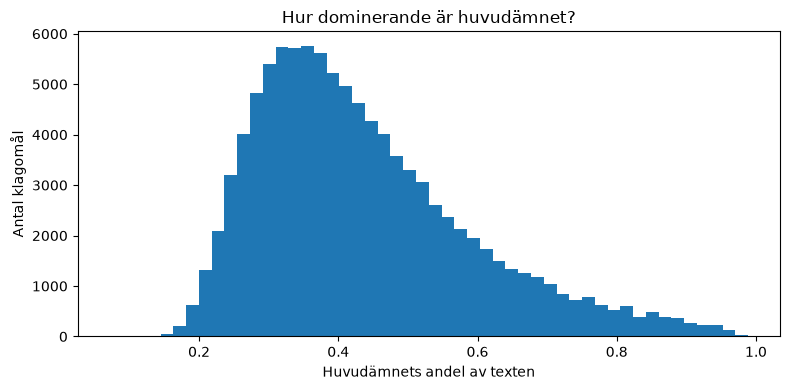

In [3]:
amnesnamn = {
    0: "Checkar och insättningar",
    1: "Kortförmåner och bonusar",
    2: "Låneansökningar och dokument",
    3: "Inkasso och kreditupplysning",
    4: "Avgifter och sena betalningar",
    5: "Bedrägliga köp",
    6: "Kundservice och uteblivna svar",
    7: "Kontoåtkomst och inloggning",
    8: "Blandat: räntor och växelkurser",
    9: "Tvister och chargebacks",
    10: "Bolån",
    11: "Betalningar och saldo",
    12: "Berättande språk",
    13: "Juridiska hänvisningar",
}

amnesfordelning = lda.transform(X_bow)   # alla klagomål, tar en stund
df["lda_amne"] = amnesfordelning.argmax(axis=1)
df["lda_andel"] = amnesfordelning.max(axis=1)
df["lda_namn"] = df["lda_amne"].map(amnesnamn)

print("Fördelning av huvudämnen:")
print(df["lda_namn"].value_counts(normalize=True).round(3))
print(f"\nMedian för huvudämnets andel: {df['lda_andel'].median():.0%}")
print(f"Andel texter där huvudämnet är under 50 %: {(df['lda_andel'] < 0.5).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["lda_andel"], bins=50)
ax.set_title("Hur dominerande är huvudämnet?")
ax.set_xlabel("Huvudämnets andel av texten")
ax.set_ylabel("Antal klagomål")
plt.tight_layout()
plt.show()

**Resultat – första tilldelningen:**

- **"Berättande språk" blev det vanligaste huvudämnet (20 %).** Ämnet består av vardagliga ord (*just, know, got, going*) som finns i de flesta texter och beskriver *hur* kunden skriver, inte *vad* klagomålet gäller.
- **Texterna är tydliga blandningar av ämnen.** Huvudämnet står i median för 40 % av texten, och för 71,5 % av klagomålen är andelen under 50 %. Det bekräftar antagandet bakom LDA: klagomål handlar ofta om flera saker samtidigt. Det innebär också att en tilldelning av *ett* huvudämne per klagomål förenklar mycket.

Histogrammet visar en topp kring 35 % och en lång svans åt höger: bara en liten andel klagomål handlar tydligt om ett enda ämne (över 80 %).

**Åtgärd:** vid tilldelning av huvudämne hoppas ämne 12 (*Berättande språk*) över, och varje klagomål får sitt mest sannolika *innehållsämne*. Alternativet att lägga till orden i stoppordslistan och träna om valdes bort, eftersom K-means och LDA då inte längre skulle bygga på samma förbehandling.

In [4]:
innehall = [i for i in range(14) if i != 12]   # alla ämnen utom "Berättande språk"
fordelning_innehall = amnesfordelning[:, innehall]

df["lda_amne"] = np.array(innehall)[fordelning_innehall.argmax(axis=1)]
df["lda_andel"] = fordelning_innehall.max(axis=1)
df["lda_namn"] = df["lda_amne"].map(amnesnamn)

print("Fördelning av huvudämnen (utan Berättande språk):")
print(df["lda_namn"].value_counts(normalize=True).round(3))
print(f"\nMedian för huvudämnets andel: {df['lda_andel'].median():.0%}")

Fördelning av huvudämnen (utan Berättande språk):
lda_namn
Inkasso och kreditupplysning       0.191
Checkar och insättningar           0.155
Kundservice och uteblivna svar     0.121
Tvister och chargebacks            0.087
Bolån                              0.085
Kontoåtkomst och inloggning        0.083
Avgifter och sena betalningar      0.061
Betalningar och saldo              0.061
Låneansökningar och dokument       0.051
Juridiska hänvisningar             0.048
Kortförmåner och bonusar           0.046
Bedrägliga köp                     0.007
Blandat: räntor och växelkurser    0.003
Name: proportion, dtype: float64

Median för huvudämnets andel: 37%


**Efter åtgärden** fördelas klagomålen på innehållsämnen. Största ämnen är *Inkasso och kreditupplysning* (19 %), *Checkar och insättningar* (16 %) och *Kundservice och uteblivna svar* (12 %). Huvudämnet står i median för 37 % av texten. *Bedrägliga köp* blev mycket litet (0,7 %), trots att K-means hittade ett kluster med 10 % obehöriga kortdebiteringar.

## 5. Jämförelse med K-means

Tre jämförelser görs:

1. **Adjusted Rand Index (ARI)** mäter hur lika två indelningar är, från 0 (inte mer lika än slumpen) till 1 (identiska). ARI beräknas mellan LDA och K-means, och mellan varje metod och CFPB:s produktindelning.
2. **Chi² och Cramér's V** mot `fick_hjalp`, på samma sätt som för K-means. Vilken indelning förklarar bäst om kunden får hjälp?
3. **Korstabell** som visar vart klagomålen i varje K-means-kluster hamnar i LDA.

Adjusted Rand Index:
  K-means mot LDA:     0.181
  K-means mot produkt: 0.172
  LDA mot produkt:     0.259

Samband med om kunden fick hjälp:
  arendetyp  chi² =  3,566  df = 13  Cramér's V = 0.188
  lda_namn   chi² =  3,182  df = 12  Cramér's V = 0.177
  Product    chi² =  5,895  df =  7  Cramér's V = 0.241


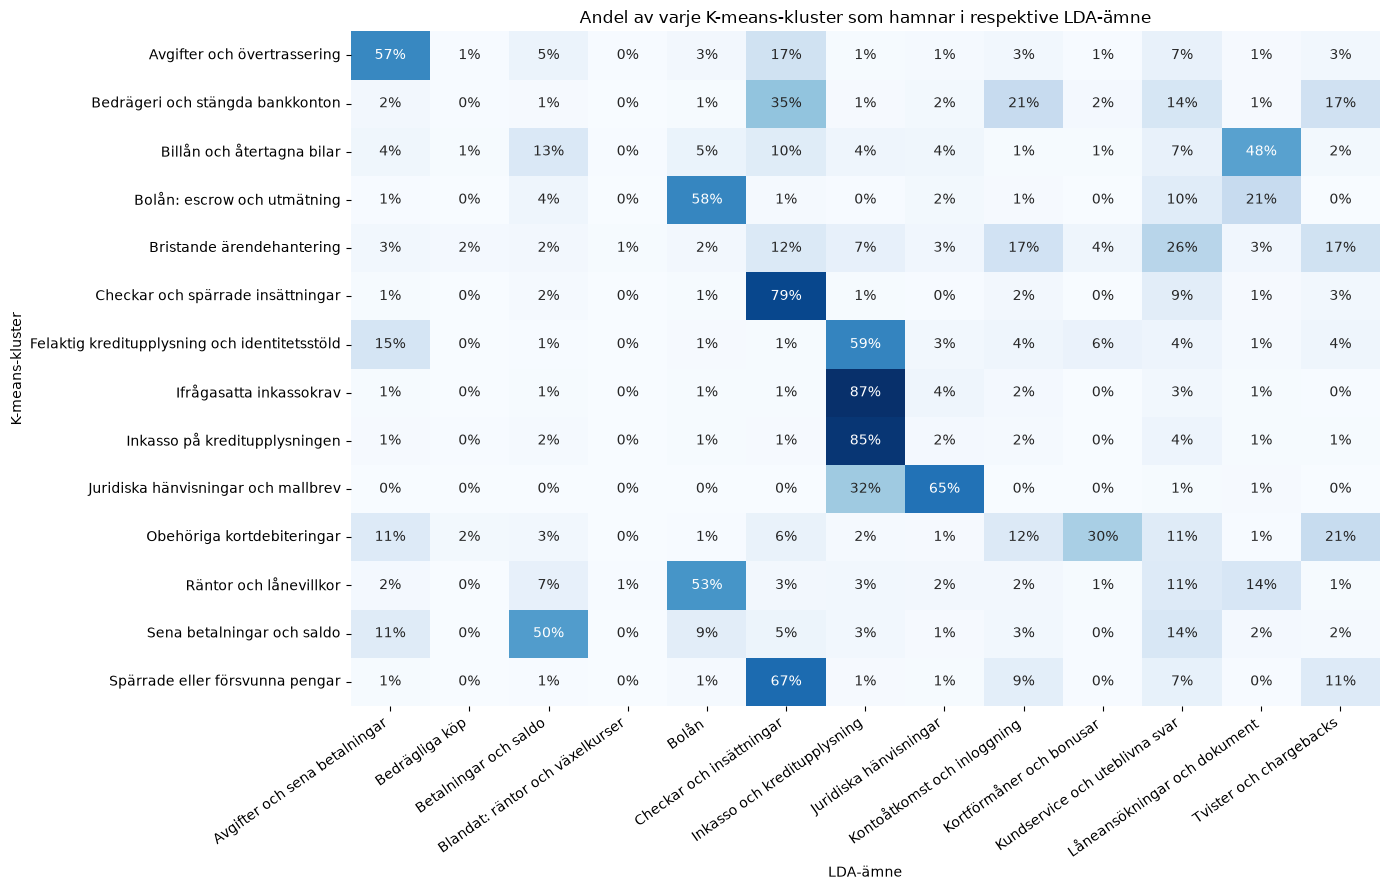

: 

In [ ]:
from sklearn.metrics import adjusted_rand_score
from scipy.stats import chi2_contingency
import seaborn as sns

# 1. ARI
print("Adjusted Rand Index:")
print(f"  K-means mot LDA:     {adjusted_rand_score(df['arendetyp'], df['lda_namn']):.3f}")
print(f"  K-means mot produkt: {adjusted_rand_score(df['arendetyp'], df['Product']):.3f}")
print(f"  LDA mot produkt:     {adjusted_rand_score(df['lda_namn'], df['Product']):.3f}")

# 2. Chi² och Cramér's V mot fick_hjalp
print("\nSamband med om kunden fick hjälp:")
for kolumn in ["arendetyp", "lda_namn", "Product"]:
    tabell = pd.crosstab(df[kolumn], df["fick_hjalp"])
    chi2, p, dof, _ = chi2_contingency(tabell)
    v = np.sqrt(chi2 / (tabell.values.sum() * (min(tabell.shape) - 1)))
    print(f"  {kolumn:10s} chi² = {chi2:6,.0f}  df = {dof:2d}  Cramér's V = {v:.3f}")

# 3. Korstabell: vart hamnar varje K-means-kluster i LDA?
kors = pd.crosstab(df["arendetyp"], df["lda_namn"], normalize="index")

fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(kors, annot=True, fmt=".0%", cmap="Blues", ax=ax, cbar=False)
ax.set_title("Andel av varje K-means-kluster som hamnar i respektive LDA-ämne")
ax.set_xlabel("LDA-ämne")
ax.set_ylabel("K-means-kluster")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

df.to_parquet("../data/complaints_lda.parquet")

**Resultat – LDA jämfört med K-means:**

| | K-means | LDA | Produkt (CFPB) |
|---|---|---|---|
| ARI mot K-means | – | 0,181 | 0,172 |
| ARI mot produkt | 0,172 | 0,259 | – |
| Cramér's V mot `fick_hjalp` | 0,188 | 0,177 | 0,241 |

- **Metoderna är överens om de tydligaste ärendetyperna:** checkar och insättningar (79 %), inkasso (85–87 %), juridiska hänvisningar (65 %), kreditupplysning (59 %), bolån (58 %) och avgifter (57 %).
- **LDA delar upp K-means största kluster.** *Bristande ärendehantering* sprids över kundservice (26 %), kontoåtkomst (17 %), tvister och chargebacks (17 %) och checkar (12 %). Det bekräftar att klustret var heterogent.
- **LDA ligger närmare produktindelningen** (ARI 0,259 mot 0,172). K-means hittar i högre grad ärendetyper som går på tvärs av produkterna, t.ex. *Räntor och lånevillkor*, som LDA till stor del lägger under *Bolån* (53 %).
- **Bedrägerier grupperas olika.** K-means samlar obehöriga kortdebiteringar i ett kluster, medan LDA sprider dem över kreditkort (30 %), tvister (21 %) och kontoåtkomst (12 %).
- **K-means förklarar utfallet något bättre** (Cramér's V 0,188 mot 0,177), men skillnaden är liten.

**Preliminär bedömning:** K-means ger fler tolkningsbara grupper (alla 14 kluster går att namnge, mot 12 av 14 LDA-ämnen) och fler ärendetyper som går på tvärs av produkterna. LDA:s styrka är att visa att klagomål ofta är blandningar av flera ämnen. Slutligt val görs efter jämförelse med HDBSCAN.